# Ciencias actuariales con datos reales: reaseguro XL y supervivencia de siniestros

Este notebook **sólo muestra resultados**. Todo el cálculo vive en el módulo
reproducible [`actuarial/`](../actuarial) y se ejecuta con una sola llamada,
`run_all()`; el mismo flujo corre desde terminal con `python -m actuarial`.

| Parte | Datos | Pregunta |
|---|---|---|
| 1. Notas | ejemplo discreto de las notas | ¿Se reproduce el Teorema (d* = 380, m* = 2748)? |
| 2. Reaseguro | 2 167 incendios reales, Copenhagen Re 1980–1990 | ¿Qué capa XL por ocurrencia minimiza el costo bajo una cota de ES? |
| 3. México | CENAPRED 2000–2024 (151 ciclones con daño) y CNSF 2015–2025 (seguro de huracán y terremoto) | ¿Qué tan pesada es la cola catastrófica mexicana, cuánto se asegura y cuánto se cede al reaseguro? |
| 4. Supervivencia | 58 056 siniestros reales de incendio, Francia 1992–2007 | ¿Cuánto tarda en liquidarse un expediente y qué valor presente tiene su reserva? |

Los datos internacionales provienen de **CASdatasets** (Dutang y Charpentier), se descargan de un commit fijo y se verifica su SHA-256.
Los mexicanos son datos abiertos oficiales (CENAPRED, CNSF) cuyos extractos derivados están en [`datos_mx/`](../datos_mx), con la URL y el SHA-256 de cada fuente en `manifest.json`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # raíz del repositorio

import pandas as pd
from actuarial.pipeline import run_all

pd.set_option("display.float_format", "{:,.4f}".format)
R = run_all()          # descarga, ajusta, simula, entrena y guarda figuras (~4 min en CPU)
re, mx, sv, fig = R["reaseguro"], R["mexico"], R["supervivencia"], R["figuras"]

## 1. Las notas: ejemplo exactamente resoluble

`notas/optimizacion_xl.py` es el programa que el `.tex` incluye con `\lstinputlisting`.
Su salida debe coincidir carácter por carácter con la que aparece en las notas.

In [2]:
print(R["notas"])

Gross expectation: 381.40
Recovery by scenario: [0, 120, 1120, 2748]
Net by scenario: [0, 380, 380, 380]
Expected recovery: 267.40
Premium: 361.73
Expected retention: 114.00
Expected total cost: 475.73
ES 95%: 380.00
Validation: PASS



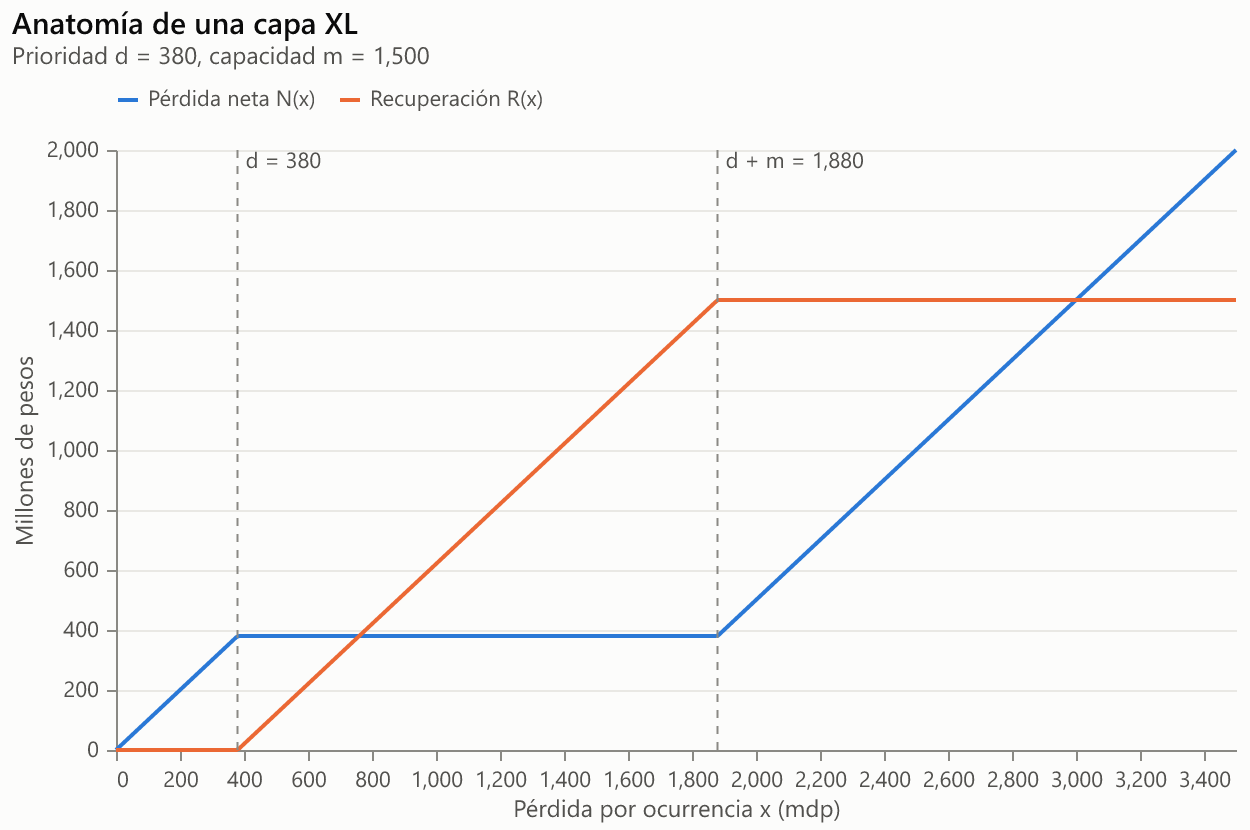

In [3]:
fig["01_capa_xl"]

## 2. Reaseguro XL calibrado con pérdidas reales (incendios daneses)

**Frecuencia.** El número anual de siniestros grandes crece alrededor de 4% por año; se ajusta un GLM de Poisson con
tendencia log-lineal y se proyecta a 1991. La sobredispersión de Pearson (≈ 2) advierte que la hipótesis de Poisson
homogéneo de las notas es optimista.

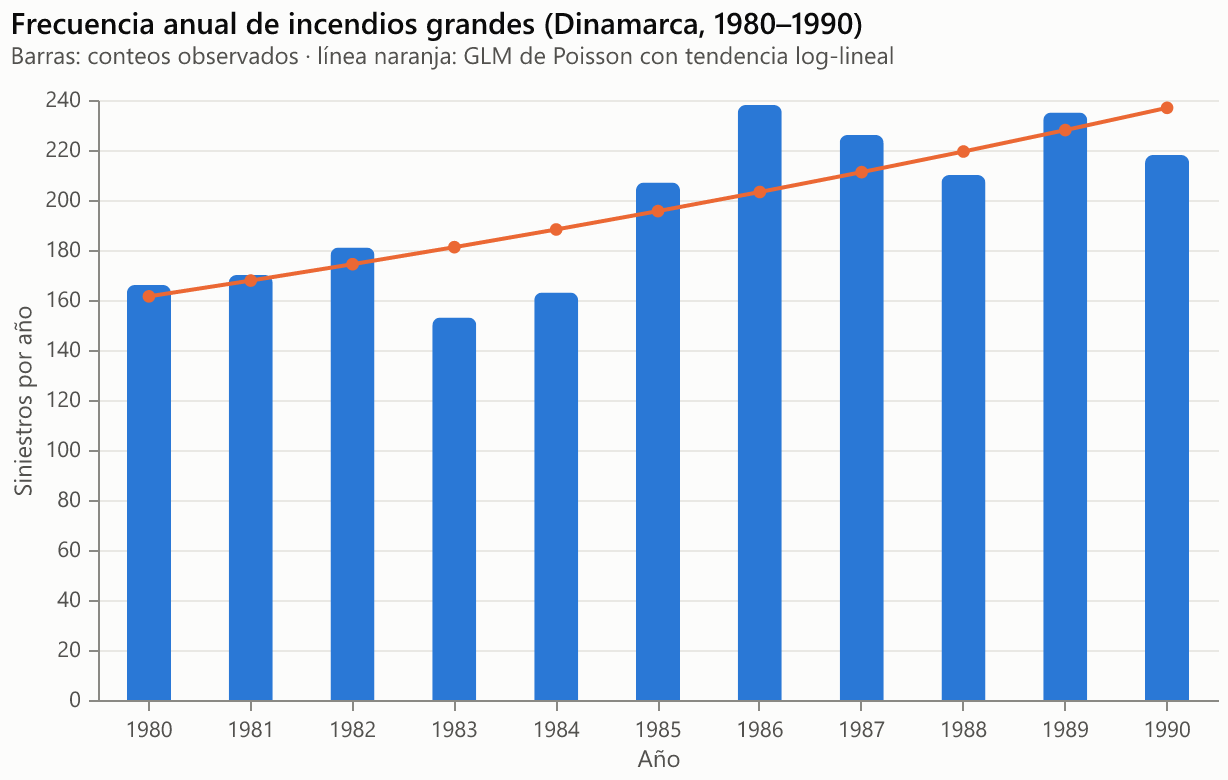

In [4]:
fig["02_frecuencia_danesa"]

**Severidad.** La lognormal subestima gravemente la cola; la Pareto de un parámetro la sobreestima. El modelo empalmado
(cuerpo empírico bajo u = 10 y GPD para los excesos) reproduce la cola; su ξ ≈ 0.5 coincide con el análisis clásico de
McNeil (1996). La función de exceso medio, creciente y casi lineal, respalda la elección del umbral.

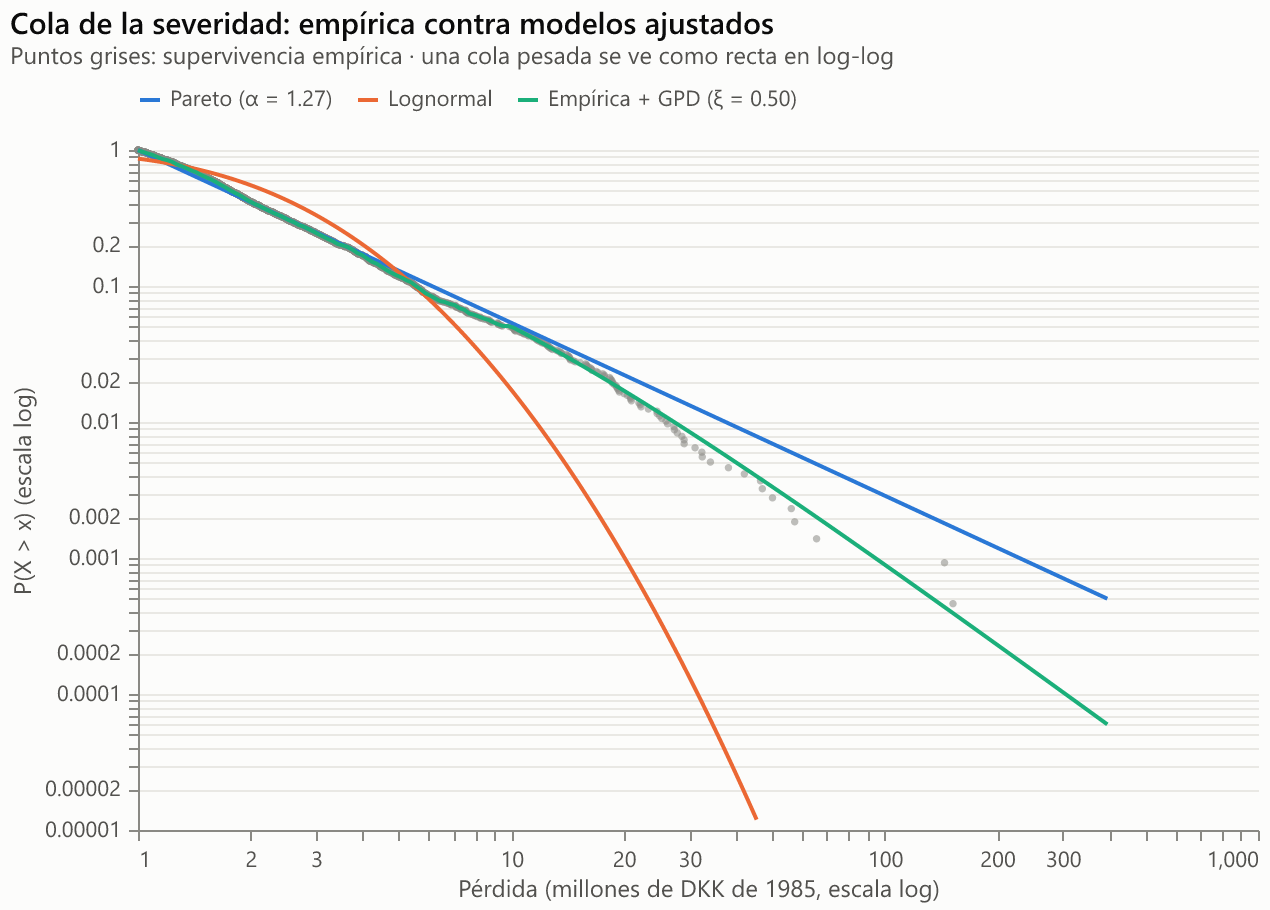

In [5]:
fig["03_cola_severidad"]

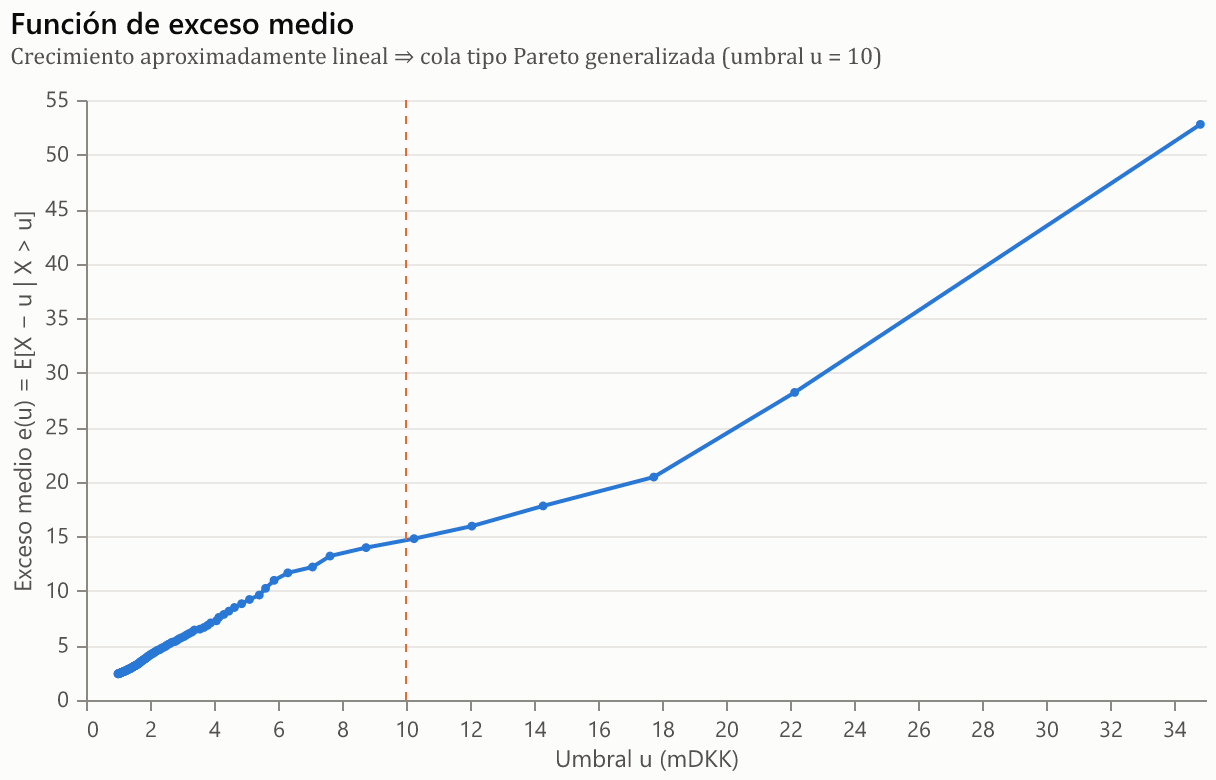

In [6]:
fig["04_exceso_medio"]

**Validación de la fórmula de prima pura por capa** (Proposición de las notas):
$\mathbb E R_{d,m}(X)=\int_d^{d+m}\overline F_X(t)\,dt$, contra el promedio empírico de las recuperaciones.

In [7]:
re["layer_check"]

,capa,empírica (media de R),"∫ S(t) dt, modelo empalmado"
0,15 xs 5,0.6536,0.6475
1,40 xs 10,0.5054,0.5193
2,80 xs 20,0.2892,0.3128
3,150 xs 50,0.1737,0.1318


**Optimización.** Con 50 000 años simulados de pérdida anual Poisson compuesta, cobertura por ocurrencia con
reinstalación ilimitada, tarifa $\Pi=(1+\theta)\mathbb E R+\gamma m$ ($\theta=0.25$, $\gamma=0.01$) y la
restricción $\mathrm{ES}_{0.99}(S^{\text{net}})\le B$ con $B = 75\%$ del ES bruto, se recorre una rejilla de $(d,m)$.

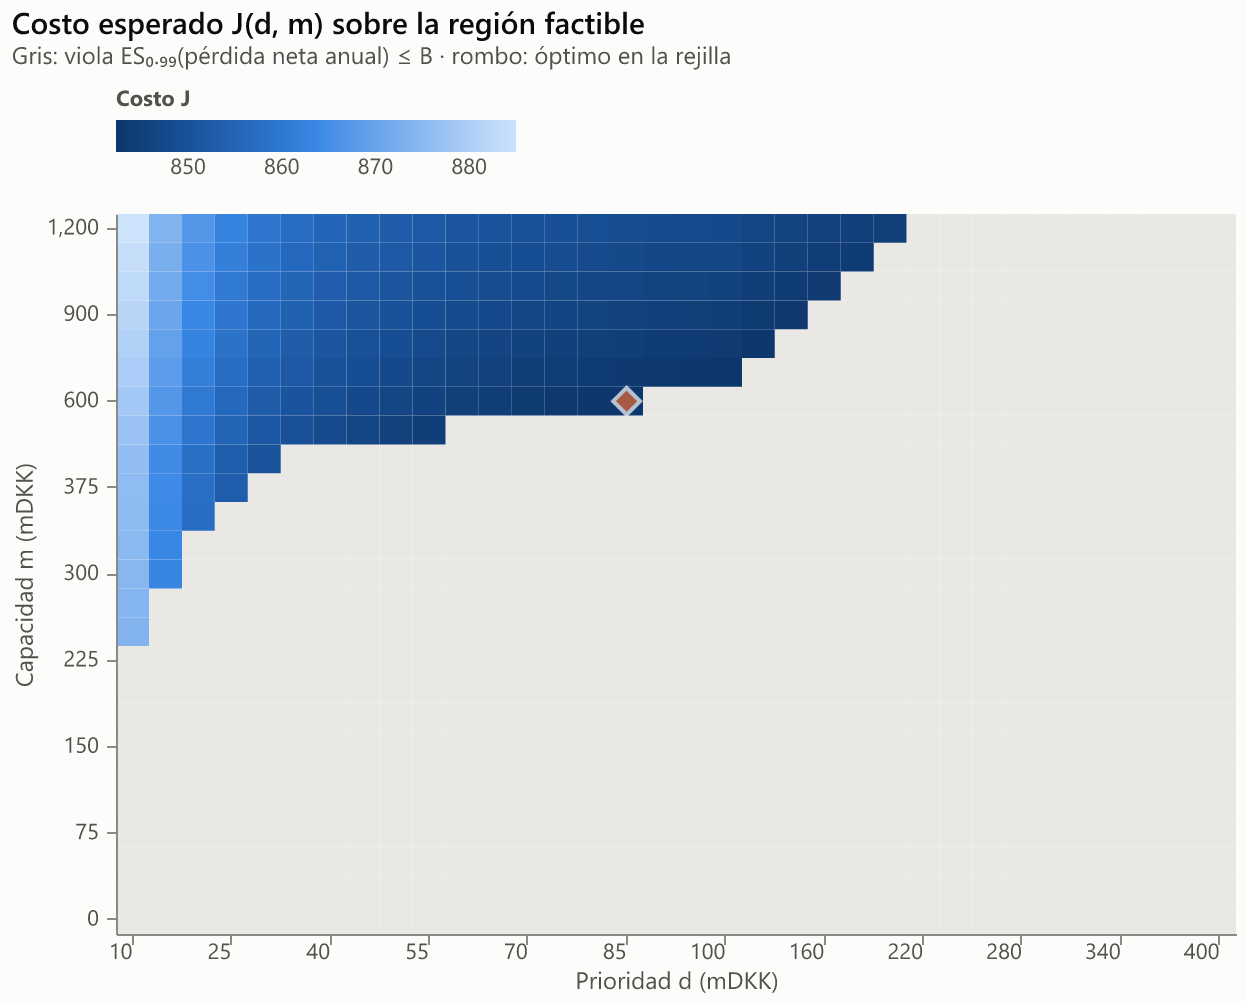

In [8]:
fig["05_costo_capa"]

In [9]:
s = re["summary"]
pd.Series({k: s[k] for k in ["lambda_1991", "gpd_xi", "gpd_xi_ic95", "E_S_bruta", "ES_0.99_bruta", "B",
                             "d_opt", "m_opt", "prima_opt", "J_opt", "ES_0.99_neta_opt"]}, dtype=object)

lambda_1991                                          246.1182
gpd_xi                                                 0.4970
gpd_xi_ic95         [0.18323540413658518, 0.7503592414870052]
E_S_bruta                                            830.4059
ES_0.99_bruta                                      1,793.7463
B                                                  1,345.3097
d_opt                                                 85.0000
m_opt                                                600.0000
prima_opt                                             35.5410
J_opt                                                842.3141
ES_0.99_neta_opt                                   1,344.8947
dtype: object

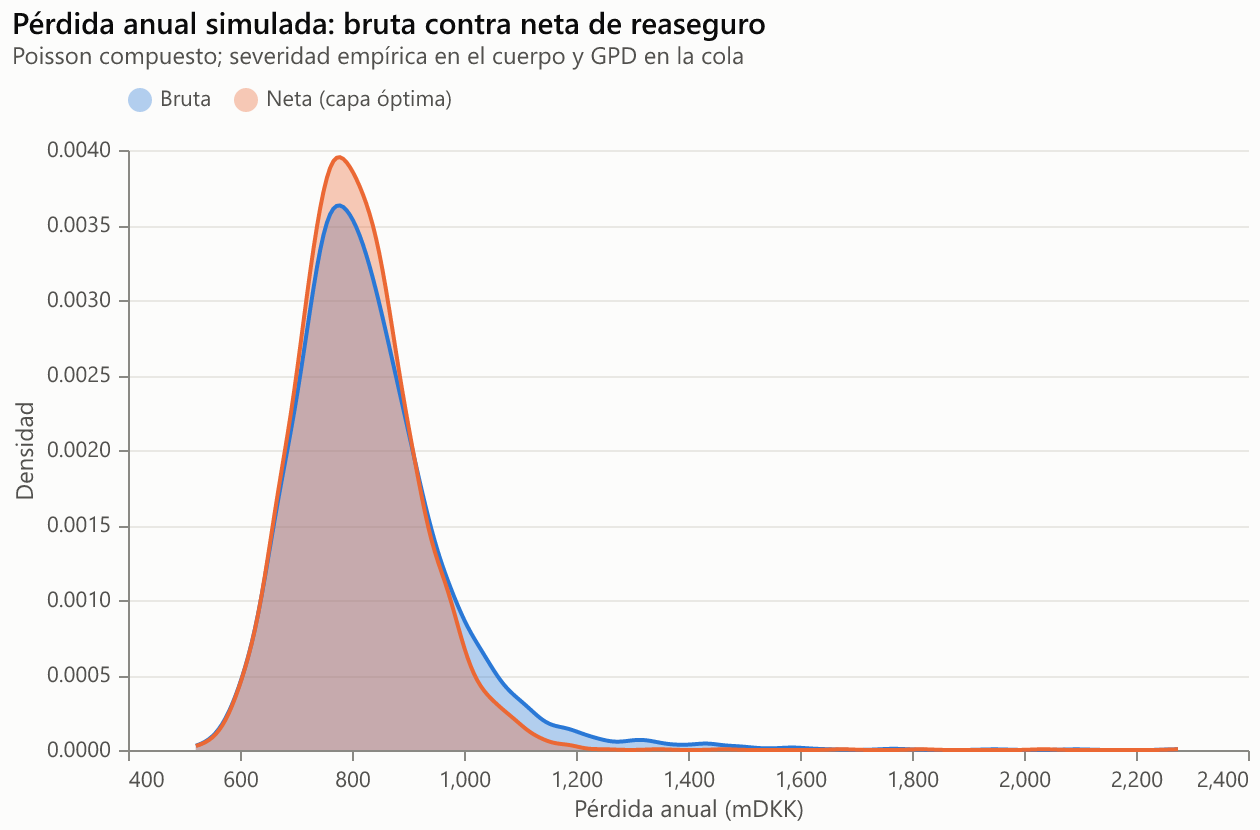

In [10]:
fig["06_perdida_anual"]

La frontera muestra el precio de la seguridad: cada reducción adicional del ES neto cuesta más que la anterior.
Igual que en las notas, sin restricción de cola el óptimo sería no reasegurar.

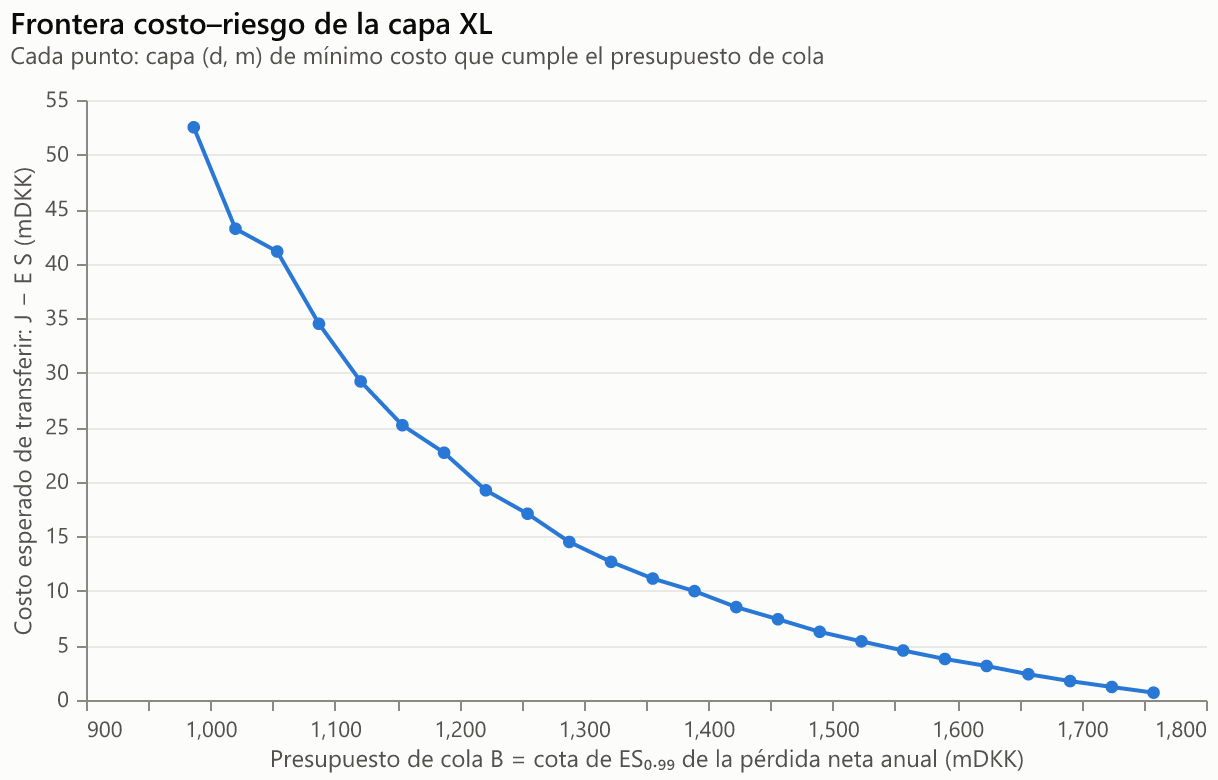

In [11]:
fig["06b_frontera"]

## 3. Casos mexicanos

**Daño económico por ciclones tropicales (CENAPRED).** Un evento es un registro con el mismo tipo y la misma fecha de inicio,
sumado sobre los estados que afectó. Los montos se deflactan a pesos de 2024. Tres años concentran la mayor parte del daño:
2005 (Stan y Wilma), 2010 (Alex, Karl y Matthew) y 2023 (Otis).

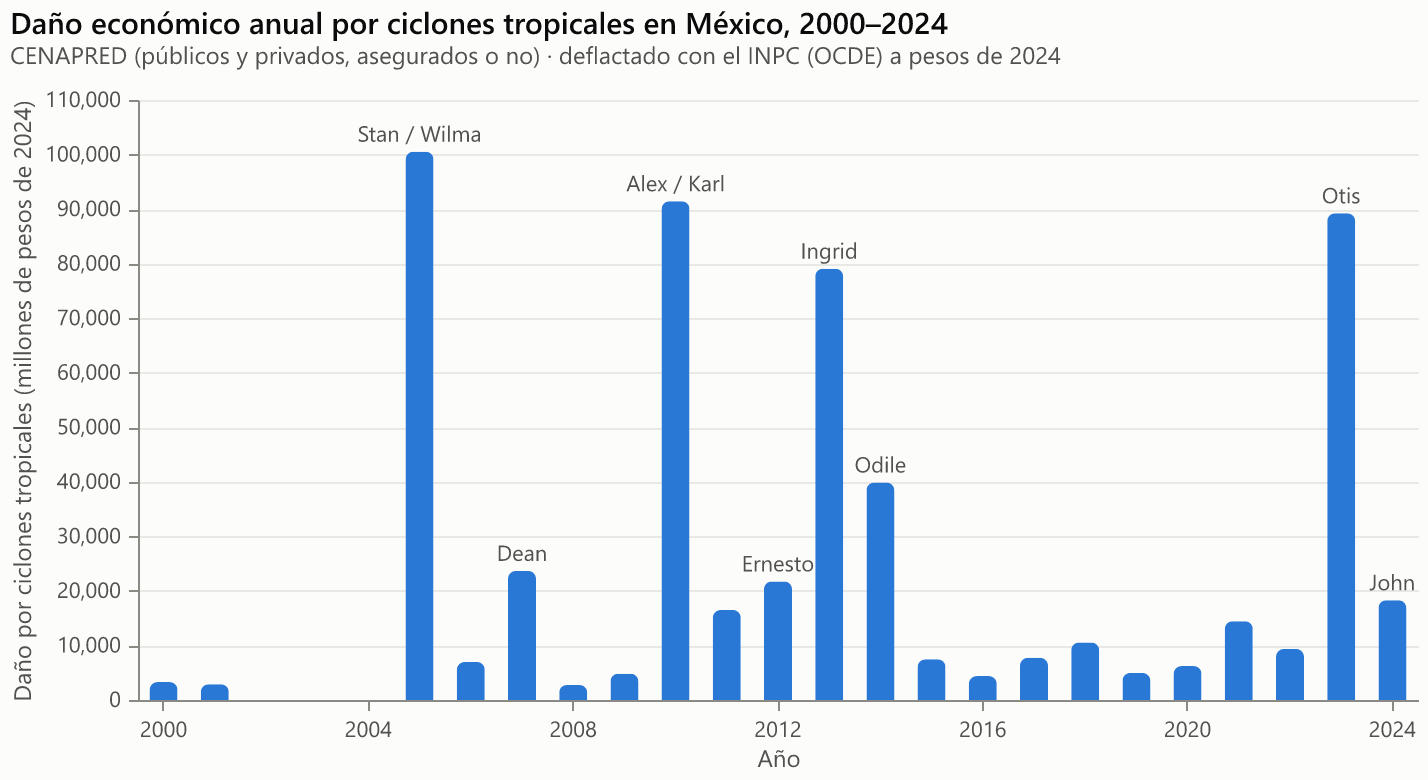

In [12]:
fig["11_mx_dano_anual"]

In [13]:
mx["top"][["inicio", "nombre", "estados", "dano_mdp", "dano_mdp_2024"]].rename(columns={"dano_mdp": "daño mdp corrientes", "dano_mdp_2024": "daño mdp 2024"})

,inicio,nombre,estados,daño mdp corrientes,daño mdp 2024
174,2023-10-24,Otis,Guerrero,"84,207.0200","87,497.6124"
25,2005-10-04,Stan,"Chiapas, Oaxaca, Puebla, Veracruz","20,241.5400","46,012.8510"
54,2010-06-30,Alex,"Coahuila, Nuevo Leon, Tamaulipas","25,032.7960","45,809.5550"
55,2010-09-17,Karl,"Puebla, Veracruz","24,931.8150","45,624.7616"
84,2013-09-14,Ingrid,"Colima, Guerrero, Jalisco, Michoacan, Nuevo Leon","27,117.4700","44,403.9419"
27,2005-10-21,Wilma,"Quintana Roo, Yucatan","18,772.9000","42,674.3543"
103,2014-09-14,Odile,"Baja California Sur, Sinaloa","24,136.2045","37,995.3335"
37,2007-08-22,Dean,"Hidalgo, Puebla, San Luis Potosi, Tlaxcala, Ve...","6,888.1290","14,533.1151"
177,2024-09-23,John,"Guerrero, Oaxaca","13,965.2100","13,965.2100"
65,2012-08-09,Ernesto,Veracruz,"5,832.6420","9,914.2934"


**Cola.** Sobre el percentil 70, la GPD estima ξ ≈ 0.96, con IC bootstrap 95% de 0.52 a 1.31: **la media podría no existir**.
La cola mexicana es mucho más pesada que la danesa (ξ ≈ 0.5). Para simular se trunca la GPD en una pérdida máxima probable
igual a 3 veces el máximo observado (Otis); es un supuesto explícito y su efecto se mide abajo.

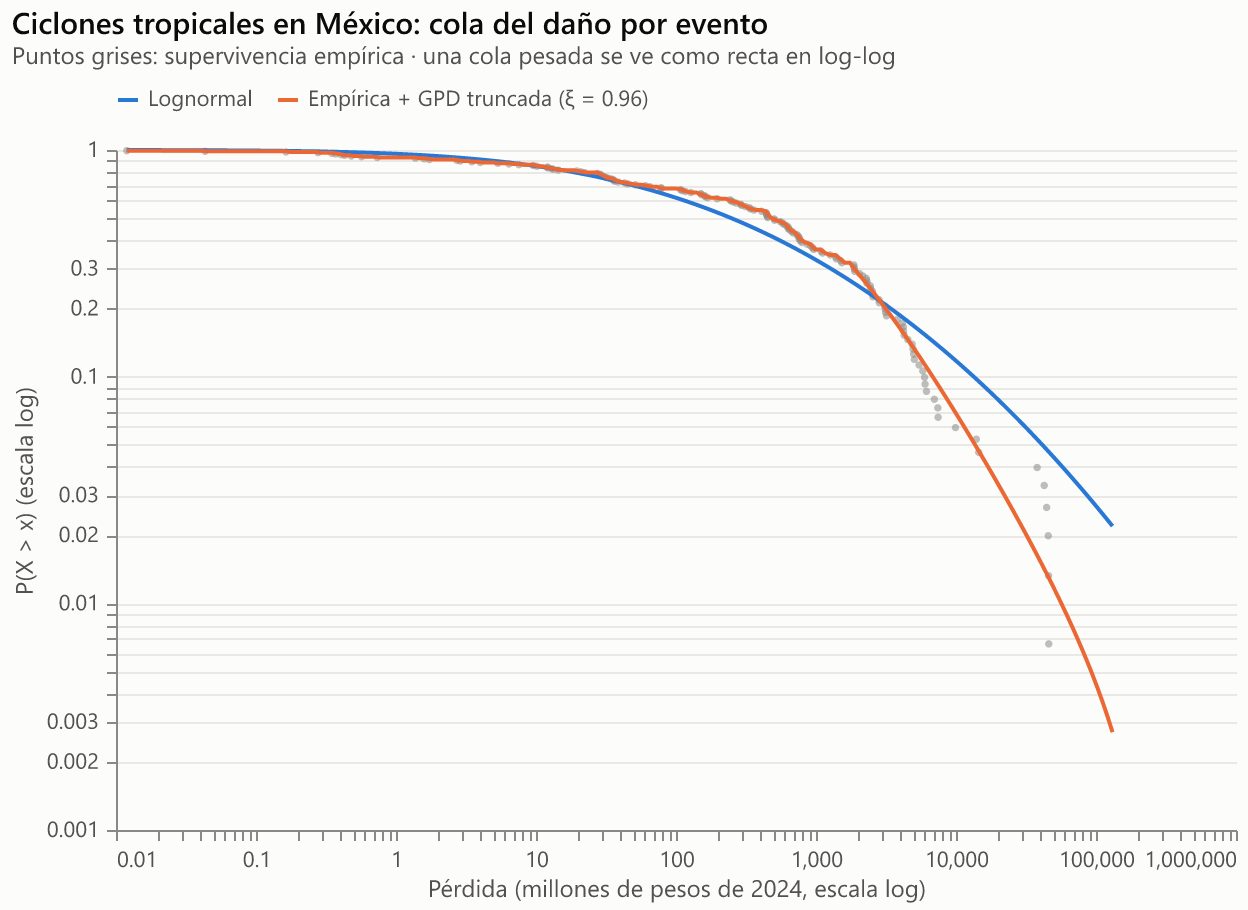

In [14]:
fig["12_mx_cola_ciclones"]

**Capa XL por ciclón.** Misma formulación que las notas: $	heta = 0.25$, $\gamma = 0.01$ y
$\mathrm{ES}_{0.99}(S^{	ext{net}}) \le 0.75\,\mathrm{ES}_{0.99}(S)$, con frecuencia Poisson de 6 eventos por año.
Las cantidades son daño económico nacional, no la cartera de una aseguradora: la capa óptima se lee como la estructura de un
bono catastrófico o de un programa paramétrico soberano, no como el contrato de una compañía.

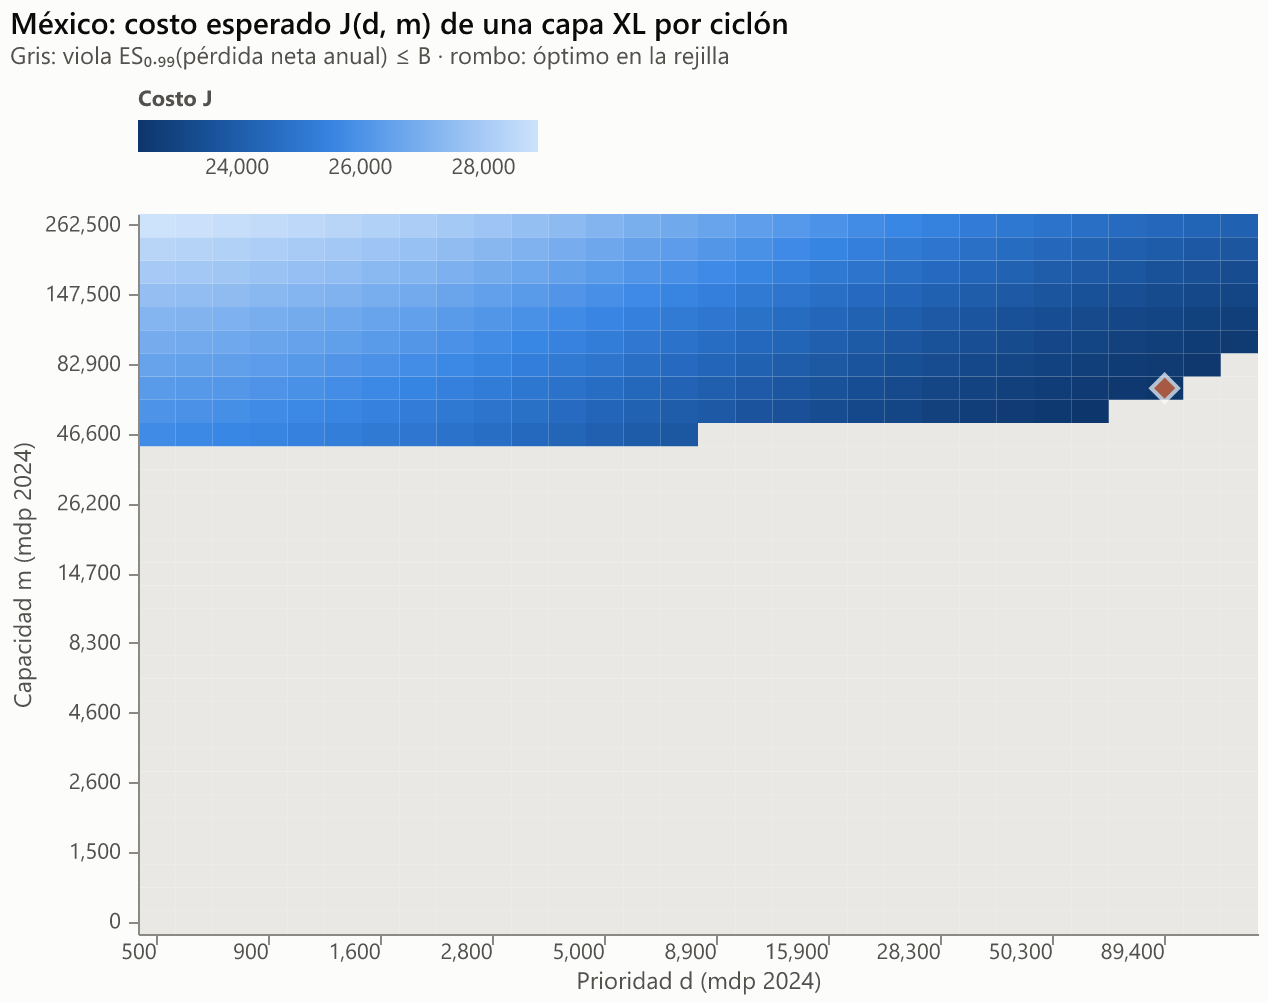

In [15]:
fig["13_mx_costo_capa"]

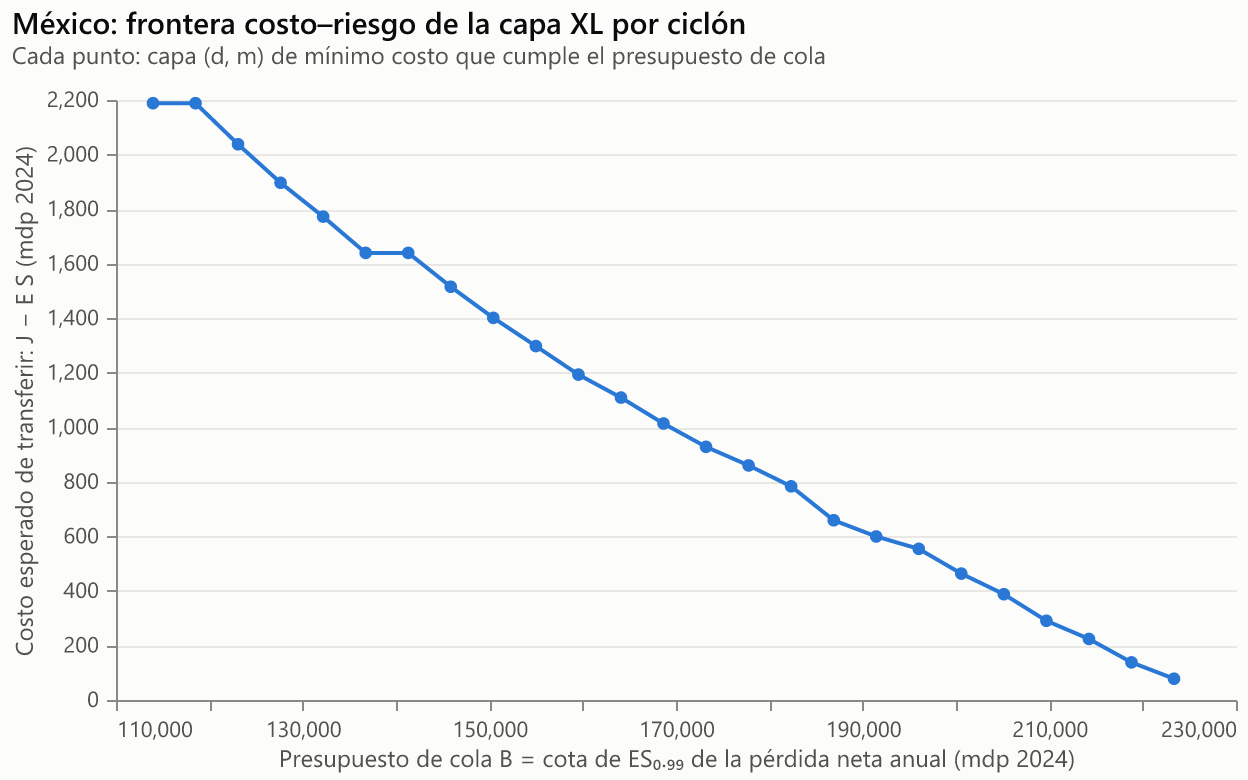

In [16]:
fig["14_mx_frontera"]

In [17]:
s = mx["summary"]
pd.Series({k: s[k] for k in ["eventos_ciclon", "lambda_eventos_por_anio", "dispersion_var_media", "gpd_xi", "gpd_xi_ic95",
                             "pml_truncacion_mdp2024", "E_S_simulada", "ES_0.99_bruta", "B", "d_opt", "m_opt", "prima_opt"]}, dtype=object)

eventos_ciclon                                                  151
lambda_eventos_por_anio                                      6.0400
dispersion_var_media                                         3.0695
gpd_xi                                                       0.9587
gpd_xi_ic95                [0.5185684394111044, 1.3111963295407925]
pml_truncacion_mdp2024                                 262,492.8373
E_S_simulada                                            21,375.7151
ES_0.99_bruta                                          227,919.4439
B                                                      170,939.5829
d_opt                                                   89,400.0000
m_opt                                                   68,400.0000
prima_opt                                                2,332.4567
dtype: object

**Sensibilidad.** La prioridad óptima depende del umbral de la GPD y, sobre todo, de la pérdida máxima probable supuesta.
Con una cola de ξ ≈ 1, la calibración de la PML es la decisión actuarial que más pesa.

In [18]:
mx["sensibilidad"]

,PML / máximo observado,cuantil del umbral u,ξ,d*,m*,prima
0,2.0000,0.6000,0.7808,"61,300.0000","50,300.0000","2,113.8625"
1,2.0000,0.7000,0.9587,"51,300.0000","42,100.0000","2,461.8078"
2,2.0000,0.8000,1.0041,"61,300.0000","50,300.0000","2,344.1921"
3,3.0000,0.6000,0.7808,"89,400.0000","68,400.0000","2,147.4698"
4,3.0000,0.7000,0.9587,"89,400.0000","68,400.0000","2,447.6144"
5,3.0000,0.8000,1.0041,"108,300.0000","68,400.0000","2,092.1115"
6,5.0000,0.6000,0.7808,"94,600.0000","81,700.0000","2,770.3967"
7,5.0000,0.7000,0.9587,"143,900.0000","100,800.0000","2,714.7858"
8,5.0000,0.8000,1.0041,"143,900.0000","100,800.0000","2,871.9323"


**Lo que el mercado asegura y cede (CNSF).** En 2023 el siniestro asegurado por huracán fue de alrededor de \$33 mil millones y
el reaseguro recuperó cerca de \$25.9 mil millones (78%). Es exactamente la no linealidad de una capa XL: la cesión casi no
existe en años ordinarios y domina en el año extremo. En 2025 la recuperación excede al movimiento del año porque incluye
pagos de reaseguro de siniestros de Otis reservados antes.

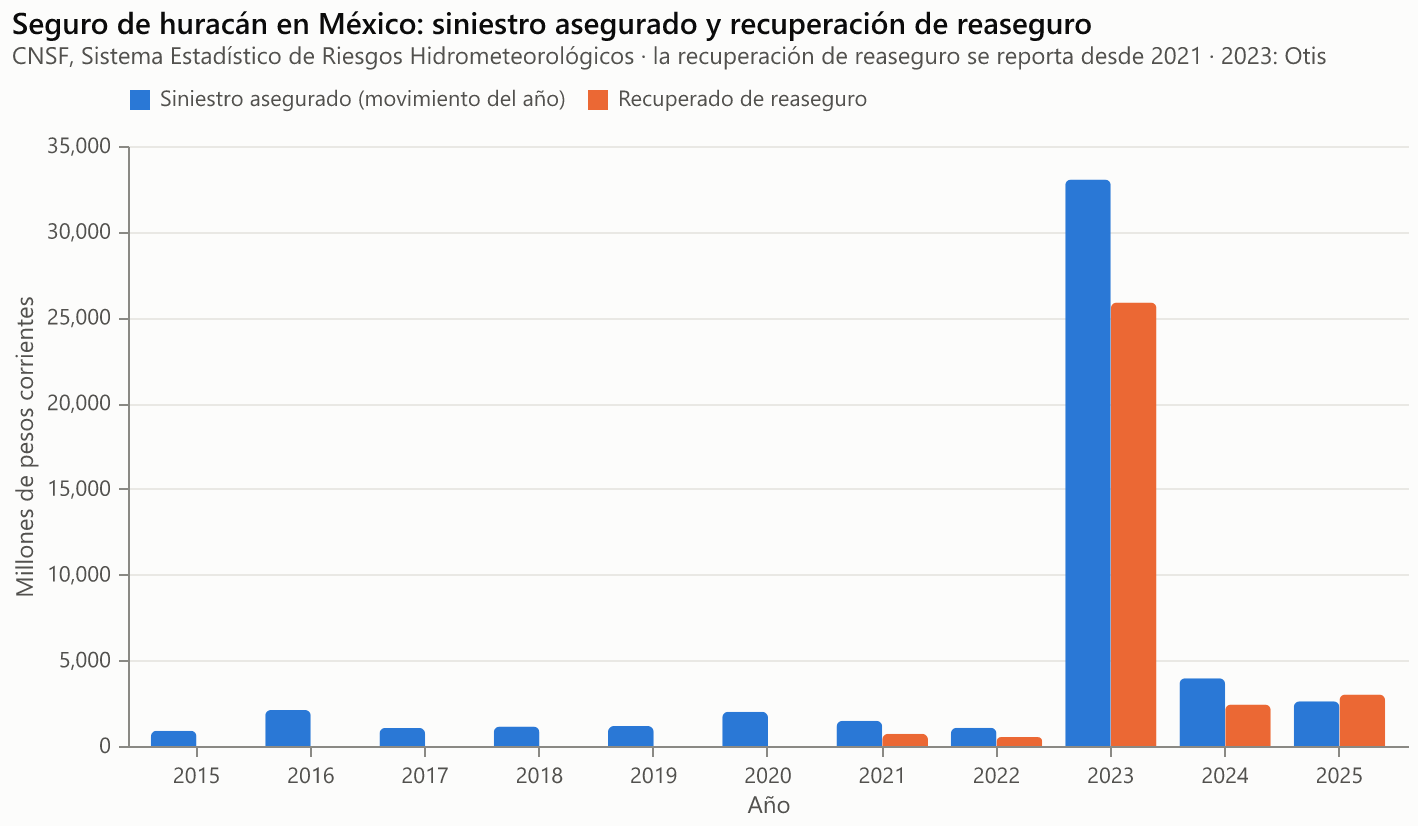

In [19]:
fig["15_mx_reaseguro_cnsf"]

**Brecha de protección.** Entre 2015 y 2024, lo asegurado por huracán equivale a cerca de un tercio del daño económico estimado por CENAPRED.

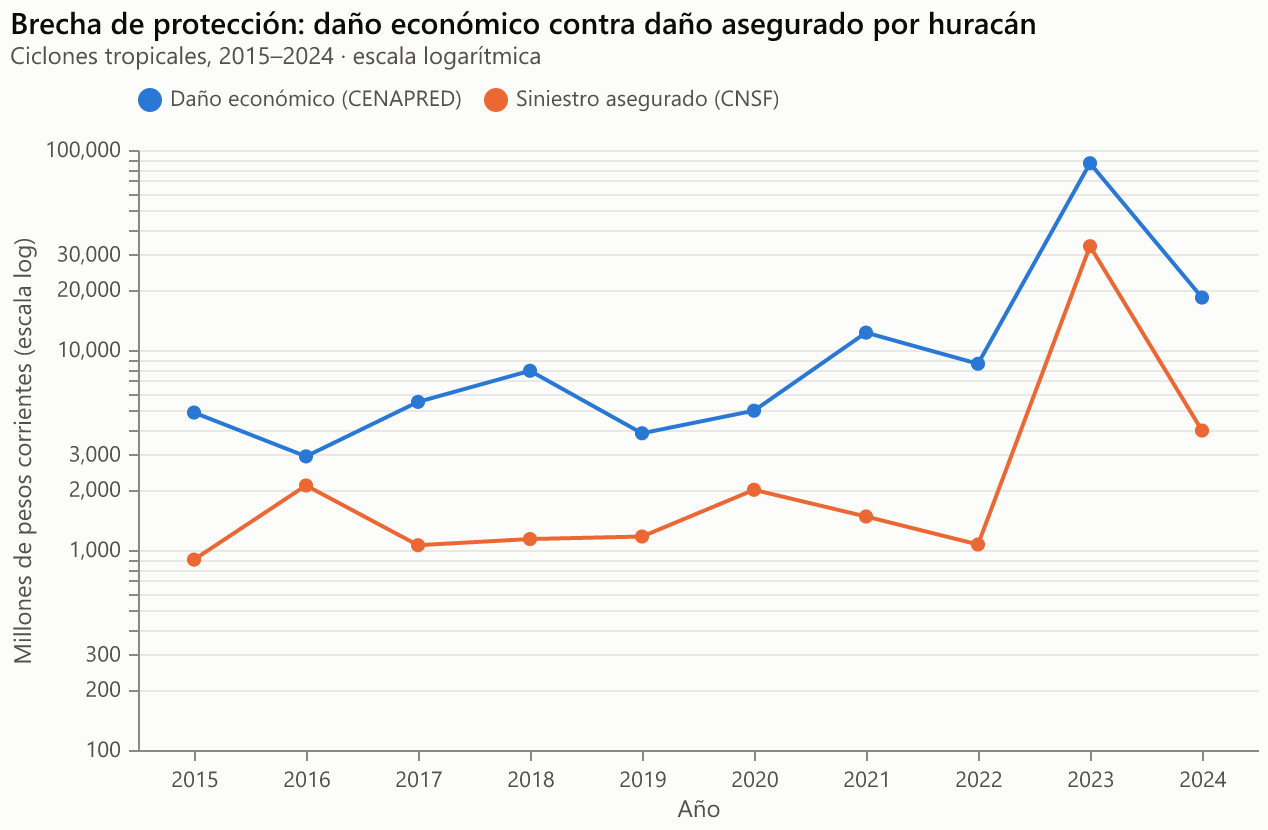

In [20]:
fig["16_mx_brecha"]

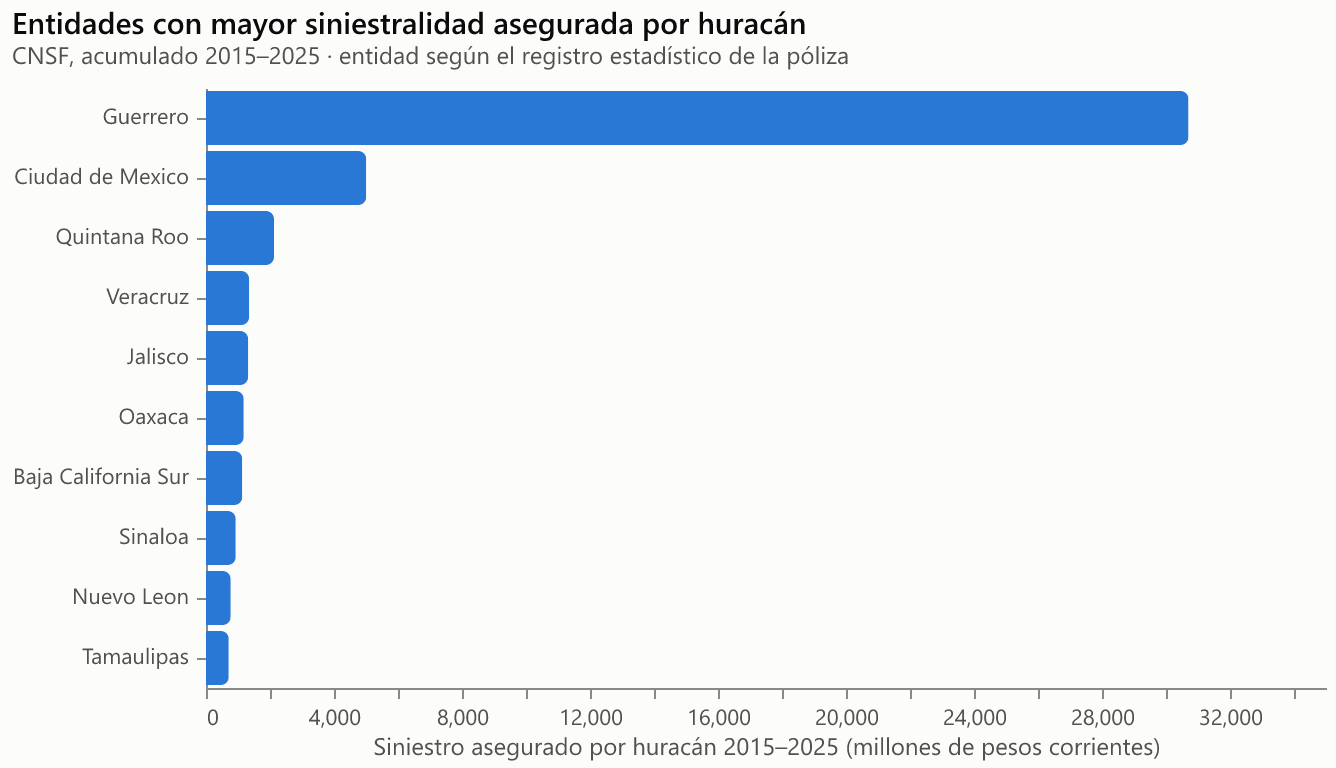

In [21]:
fig["17_mx_entidades"]

## 4. Supervivencia neuronal de expedientes con datos reales

El script sintético original (`scripts/actuarial_survival_nn_synthetic.py`) se lleva a siniestros reales:
el **evento** es la liquidación (primer cierre anual con pagado = incurrido) y la **censura** es administrativa
(expedientes abiertos al cierre de 2007). Se comparan Kaplan–Meier, una regresión logística en tiempo discreto y
una red neuronal con la misma verosimilitud censurada. En lugar del Brier de casos completos, que está sesgado, se usa el
**Brier ponderado por IPCW**.

In [22]:
pd.Series(sv["summary"])

n_siniestros                58056
liquidados                  54082
censurados                   3974
reabiertos_tras_liquidar     1169
n_entrenamiento             34833
n_validación                 8708
n_prueba                    14515
épocas_mejor_validación      1821
dtype: int64

In [23]:
sv["metrics"]

,modelo,NLL prueba (por siniestro),Brier IPCW medio
0,Kaplan–Meier,1.4815,0.1229
1,Logística (GLM),1.2876,0.1043
2,Red neuronal,1.2270,0.0988


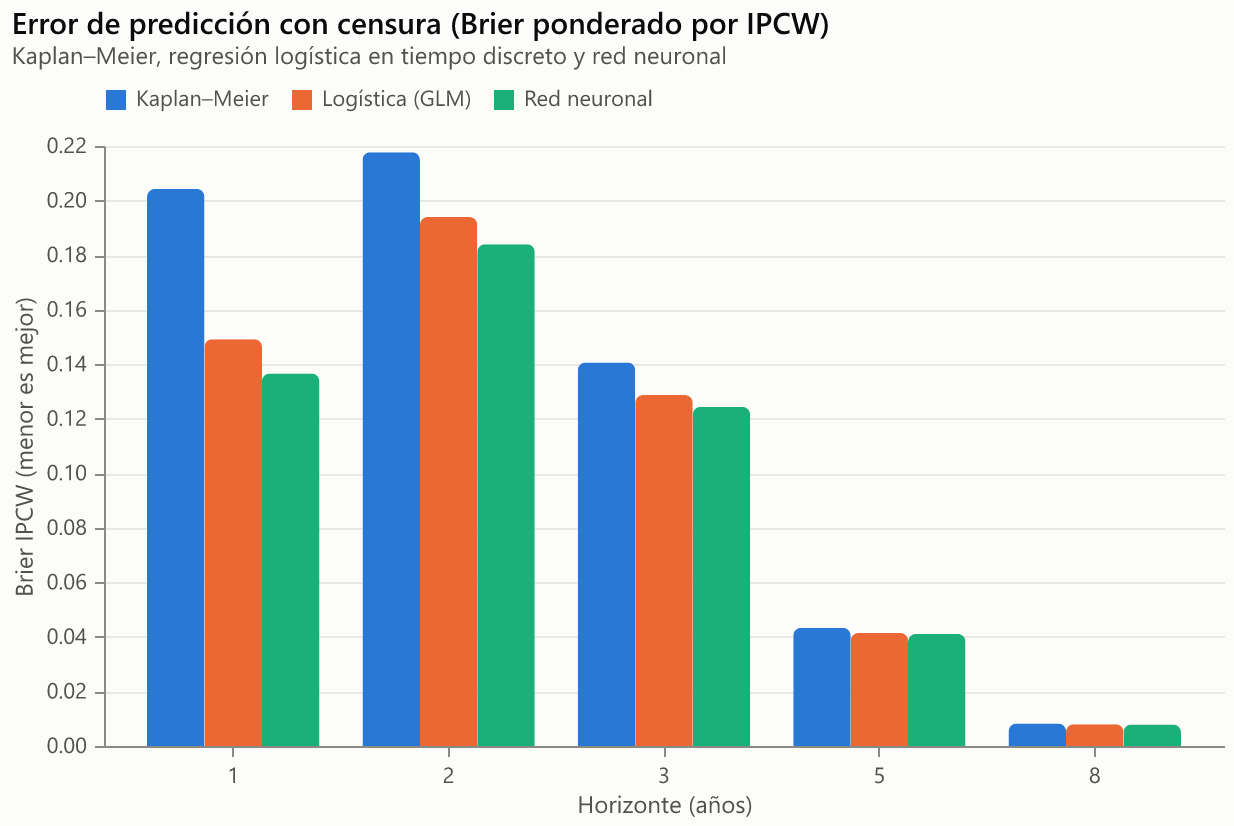

In [24]:
fig["10_brier_ipcw"]

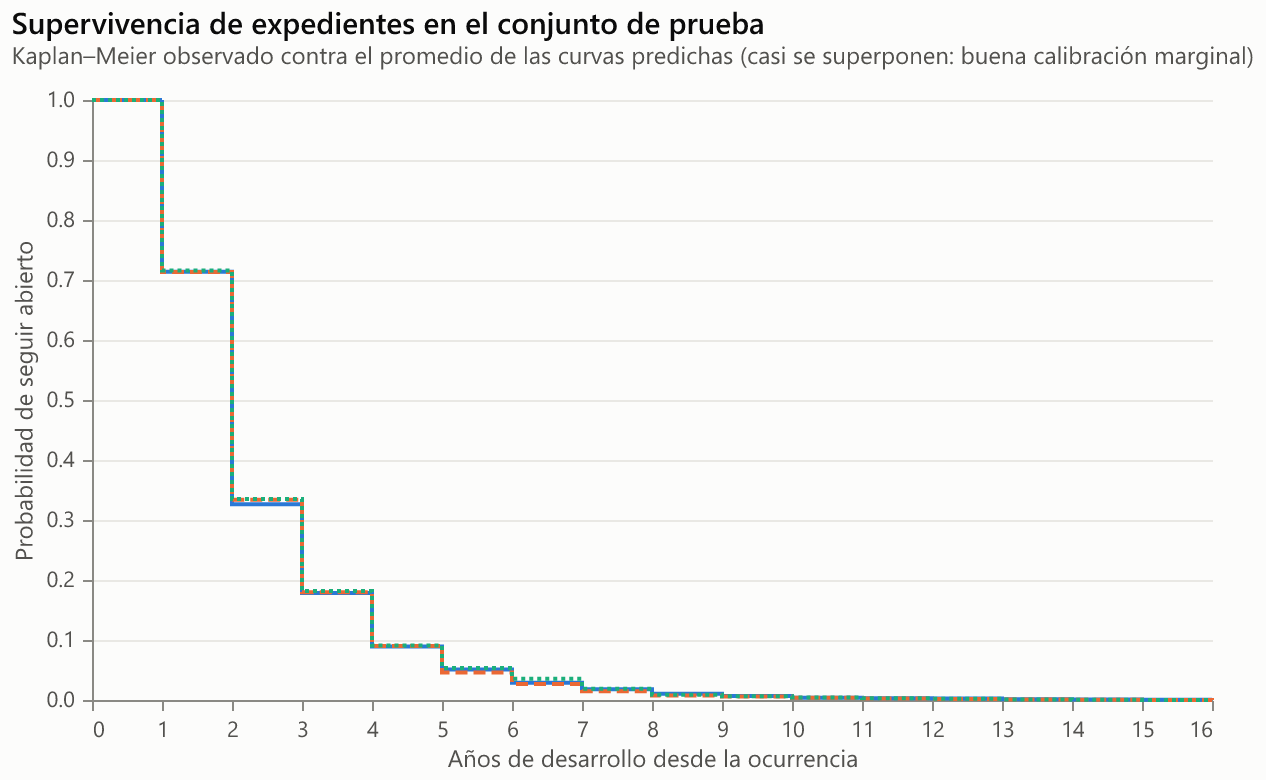

In [25]:
fig["07_supervivencia_ajuste"]

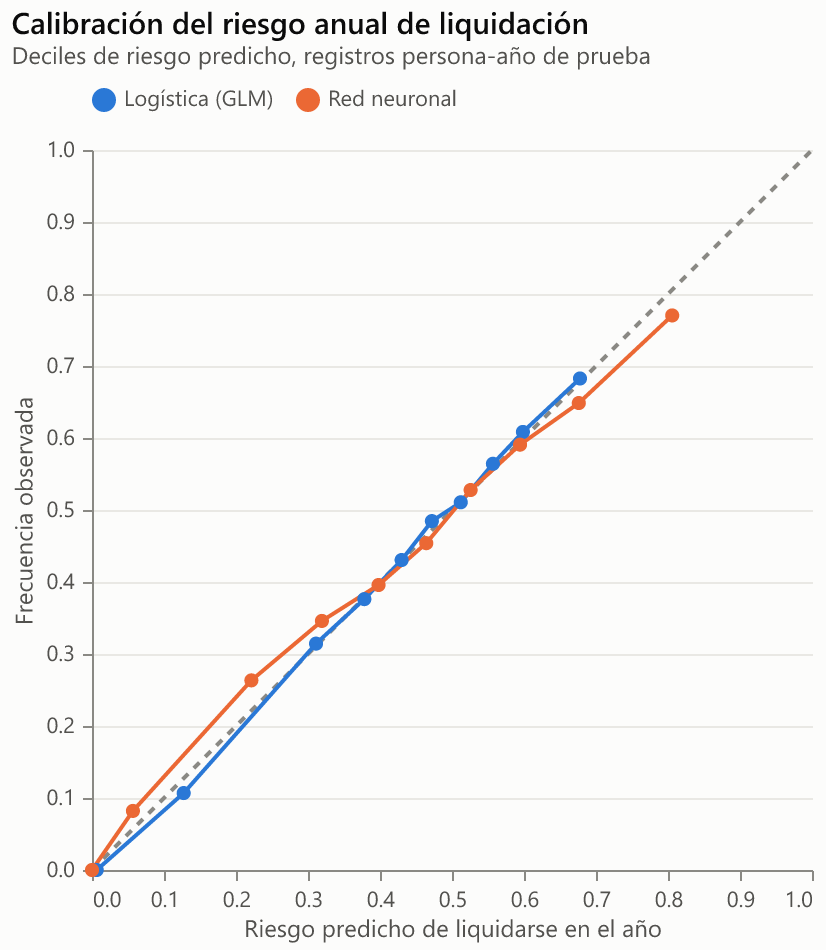

In [26]:
fig["09_calibracion"]

**Perfiles.** Un mismo tipo de riesgo, variando sólo el incurrido inicial: los siniestros grandes tardan años
más en cerrarse, lo que alarga la duración financiera de su reserva.

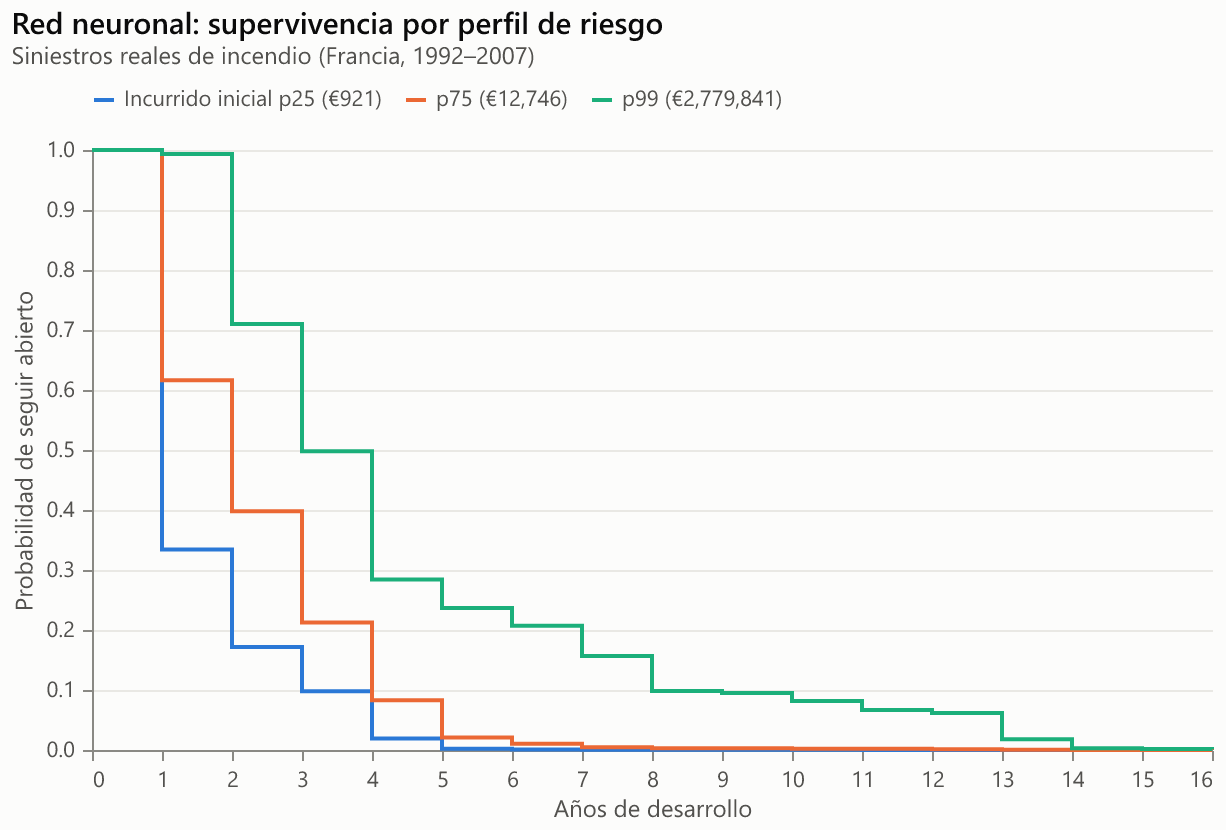

In [27]:
fig["08_supervivencia_perfiles"]

**Reserva de casos descontada.** Para los expedientes de prueba abiertos al cierre del segundo año de desarrollo,
la reserva de casos (incurrido menos pagado) se descuenta al 3% anual con la distribución condicional del tiempo de
liquidación predicha por la red, suponiendo que el saldo se paga al liquidar. Esto es una reserva de casos descontada, **no**
una reserva IBNR.

In [28]:
pd.Series(sv["reserve"])

a                                            2.0000
tasa                                         0.0300
siniestros_abiertos                      4,268.0000
reserva_casos                      289,259,844.8700
reserva_descontada                 264,898,224.6503
factor_descuento_medio_ponderado             0.9158
años_esperados_a_liquidar_medio              2.1838
masa_no_liquidada_en_K                       0.0003
dtype: float64

## Alcance

* CENAPRED mide daño económico total (público y privado, asegurado o no) con la metodología DaLA de la CEPAL; la CNSF reporta
  movimientos anuales de siniestros asegurados del mercado. No son la misma magnitud y su cociente es sólo indicativo.
* Los datos daneses están en millones de DKK de 1985; el ejemplo de las notas está en millones de pesos y su escala proviene
  de cifras públicas de AXA y AMIS. Ninguno reconstruye un contrato real.
* `freclaimset3fire9207` es una muestra aleatorizada de un asegurador francés no identificado (ver la documentación de CASdatasets).
* Tarifa, $\theta$, $\gamma$, $\alpha$ y $B$ son supuestos didácticos, no cotizaciones de mercado ni la regla de capital de la CNSF.